# Platform revenue intelligence with Timestral

An executable demonstration of the [KPI intelligence proposal](timestral_kpi_intelligence_proposal.md), using **synthetic platform data**, rather than individual CLTV.

We ask: which historical KPI groups add information about subsequent platform revenue, how early is it available, and which observed changes deserve investigation? The notebook implements group addition/removal, feature-delay experiments, calibrated anomaly diagnostics, and exact accounting decomposition.

**All business relationships and incidents below are fictional.** Predictive improvement is not causal impact. The generator intentionally contains delayed relationships, but Timestral is not guaranteed to recover them or beat a seasonal baseline.

In [1]:
from pathlib import Path
import sys, json
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from huggingface_hub import snapshot_download
from timestral import TimestralForecaster
from platform_revenue import (make_sample, GROUPS, HORIZONS, ANOMALY_TARGETS,
                              experiment_specs, run_study, decomposition)

print("Python:", sys.executable)
print("Timestral:", version("timestral"), "| PyTorch:", torch.__version__)
assert Path(sys.prefix).name == "llm", "Select the Python (llm) notebook kernel."
torch.set_num_threads(2)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .2})
OUT = Path("artifacts/platform_revenue")
OUT.mkdir(parents=True, exist_ok=True)

/Users/linghuang/miniconda3/envs/llm/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python: /Users/linghuang/miniconda3/envs/llm/bin/python
Timestral: 1.0.0 | PyTorch: 2.14.0


## 1. Generate a sample platform

Five years of daily observations include audience, content supply, discovery, engagement/social, and monetization. Dates start in 2021 and are simulated, not historical platform records. Persistent random fluctuations, weekly/annual seasonality and a predetermined monthly campaign create realistic variation.

The fictional generator makes recommendation quality influence room joins immediately, watch time after seven days, and repeat participation through further delays. Paying conversion depends on quality and repeat participation with delays. Revenue is exactly `DAU × payer rate × revenue per payer`. Paying users are continuous expected counts in this simulation.

Three documented incidents create a discovery decline, a supply decline, and a payment outage. **Event labels and hidden quality are never forecasting inputs.** These labels support retrospective inspection only; they do not prove every flagged day has the correct explanation.

In [2]:
df = make_sample(seed=2026)
np.testing.assert_allclose(df.revenue, df.dau * df.payer_rate * df.revenue_per_payer)
assert df.dt.is_monotonic_increasing and df.dt.is_unique
assert not df.isna().any().any()
df.to_csv(OUT / "sample_daily_kpis.csv", index=False)
display(pd.DataFrame({"group": list(GROUPS), "historical KPIs": [", ".join(v) for v in GROUPS.values()]}))
display(df.tail(5))
print(f"{len(df):,} days; {df.dt.min().date()} to {df.dt.max().date()}")

,group,historical KPIs
0,audience,"dau, returning_viewer_rate"
1,supply,"active_rooms, content_diversity"
2,discovery,"views_per_dau, ctr, room_join_rate"
3,engagement,"watch_minutes_per_join, repeat_participation_r..."
4,monetization,"payer_rate, revenue_per_payer"


,dt,dau,returning_viewer_rate,active_rooms,content_diversity,views_per_dau,ctr,room_join_rate,watch_minutes_per_join,repeat_participation_rate,follow_rate,payer_rate,revenue_per_payer,paying_users,revenue,cumulative_revenue,event
1820,2025-12-26,36922.918403,0.564325,1221.979102,0.625111,6.326496,0.052245,0.325215,18.311359,0.443543,0.031651,0.055302,32.677664,2041.896407,66724.403984,1.116026e+08,none
1821,2025-12-27,35886.111927,0.565674,1148.957543,0.639117,6.202469,0.053317,0.328888,17.680150,0.423512,0.026407,0.054255,32.662574,1947.010965,63594.390559,1.116662e+08,none
1822,2025-12-28,36311.399616,0.570585,1122.482485,0.635383,6.460089,0.053043,0.330192,18.757806,0.430800,0.026351,0.054092,32.283254,1964.165896,63409.666207,1.117296e+08,none
1823,2025-12-29,37648.125854,0.547954,1208.900013,0.588861,6.425370,0.053433,0.321431,17.419944,0.418382,0.026947,0.052225,31.870054,1966.186995,62662.485195,1.117922e+08,none
1824,2025-12-30,38315.753827,0.578249,1279.723148,0.603860,6.300728,0.052437,0.324791,17.563786,0.425162,0.034790,0.054479,32.244632,2087.401852,67307.504365,1.118595e+08,none


1,825 days; 2021-01-01 to 2025-12-30


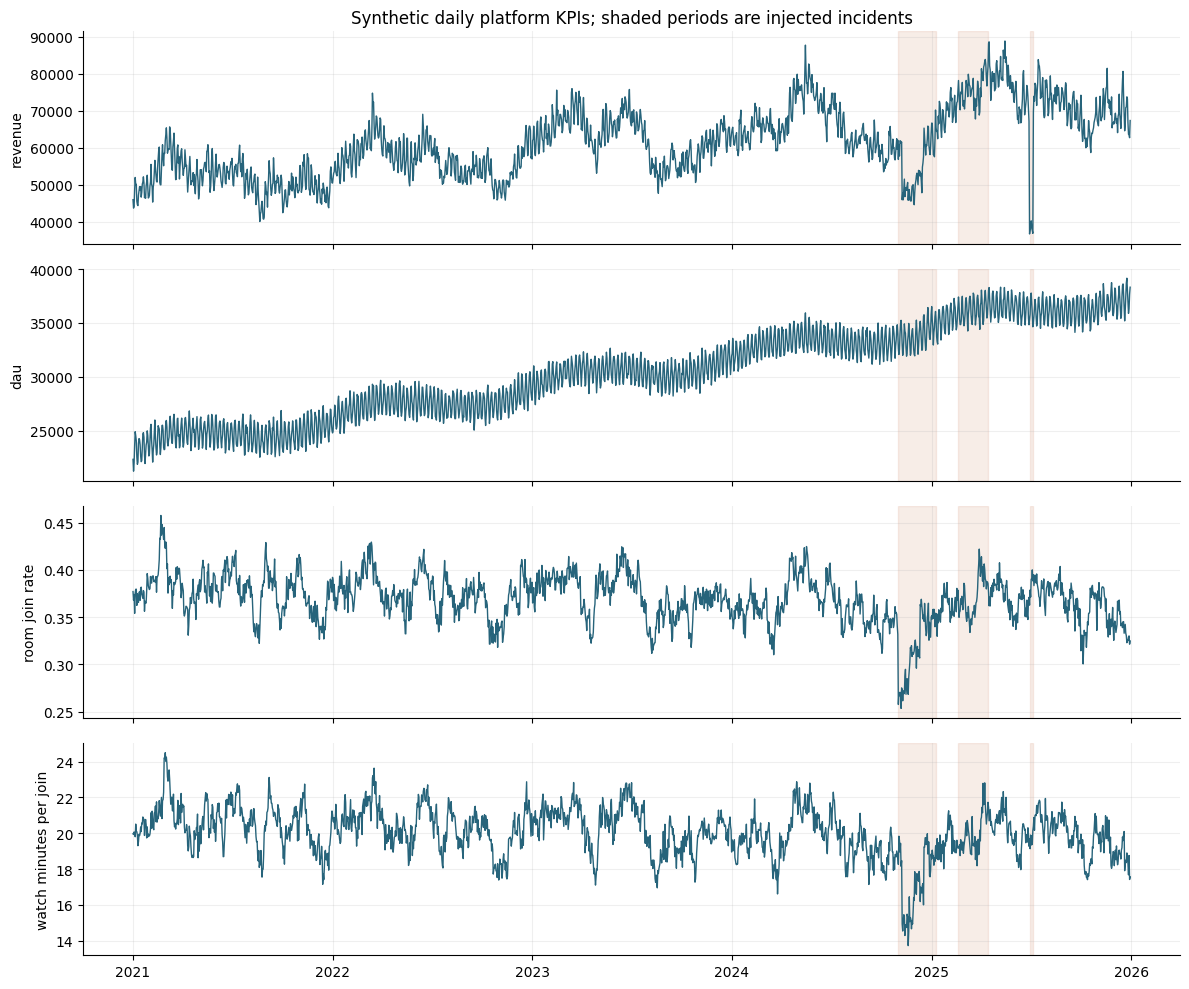

,dt,cumulative_revenue,revenue_l1,revenue_l7,revenue_l30,revenue_l365
1822,2025-12-28,1.117296e+08,63409.666207,482407.398133,2.075344e+06,2.615453e+07
1823,2025-12-29,1.117922e+08,62662.485195,474254.204798,2.071630e+06,2.615911e+07
1824,2025-12-30,1.118595e+08,67307.504365,470568.039089,2.071981e+06,2.616619e+07


In [3]:
fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
for ax, metric in zip(axes, ["revenue", "dau", "room_join_rate", "watch_minutes_per_join"]):
    ax.plot(df.dt, df[metric], lw=1, color="#27647b")
    ax.set_ylabel(metric.replace("_", " "))
    for _, event in df[df.event != "none"].groupby("event"):
        ax.axvspan(event.dt.min(), event.dt.max(), alpha=.12, color="#c46d41")
axes[0].set_title("Synthetic daily platform KPIs; shaded periods are injected incidents")
plt.tight_layout(); plt.show()

# L1/L7/L30/L365 reporting; cumulative totals are never prediction targets.
report = pd.DataFrame({"dt": df.dt, "cumulative_revenue": df.revenue.cumsum()})
for window in [1, 7, 30, 365]:
    report[f"revenue_l{window}"] = df.revenue.rolling(window, min_periods=window).sum()
report.to_csv(OUT / "revenue_reporting_windows.csv", index=False)
display(report.tail(3))

## 2. Freeze the chronological experiment

Each origin uses the preceding **365 days**, forecasts the following **90 days**, and evaluates summed daily point predictions at **7/30/90 days**. Origins are 90 days apart, so evaluated target windows do not overlap within each horizon.

The first three origins are development, the next nine are calibration, and the final four are evaluation. Specifications below are fixed before evaluation; we do not select a winning model on the test outcomes. These four evaluation origins are illustrative and too few for strong generalization claims.

Every Timestral variant receives the same known calendar: weekend, annual sine/cosine, and the predetermined campaign schedule. Revenue and all behavioral signals stop before the cutoff. Delayed-signal experiments keep audience and revenue current while withholding the newest discovery/engagement observations. No realized future KPI is supplied as a known covariate.

Revenue-only refers to revenue plus this common calendar. Seasonal naive repeats the preceding week without calendar inputs. No fine-tuning is performed.

In [4]:
origins = list(range(365, 1716, 90))
partitions = pd.DataFrame({"cutoff": origins, "origin": df.dt.iloc[origins].to_numpy(),
                           "split": ["development"] * 3 + ["calibration"] * 9 + ["evaluation"] * 4})
partitions["last_target_day"] = partitions.origin + pd.Timedelta(days=89)
assert (partitions.origin.iloc[1:].reset_index(drop=True) >
        partitions.last_target_day.iloc[:-1].reset_index(drop=True)).all()
display(partitions)
specs = experiment_specs()
display(pd.DataFrame([{"experiment": k, "past_covariates": ", ".join(cols) or "none",
                        "signal_delay_days": delay}
                       for k, (cols, delay, _) in specs.items()]))
partitions.to_csv(OUT / "partitions.csv", index=False)

,cutoff,origin,split,last_target_day
0,365,2022-01-01,development,2022-03-31
1,455,2022-04-01,development,2022-06-29
2,545,2022-06-30,development,2022-09-27
3,635,2022-09-28,calibration,2022-12-26
4,725,2022-12-27,calibration,2023-03-26
5,815,2023-03-27,calibration,2023-06-24
6,905,2023-06-25,calibration,2023-09-22
7,995,2023-09-23,calibration,2023-12-21
8,1085,2023-12-22,calibration,2024-03-20
9,1175,2024-03-21,calibration,2024-06-18


,experiment,past_covariates,signal_delay_days
0,revenue_only,none,0
1,audience,"dau, returning_viewer_rate",0
2,audience_plus_supply,"dau, returning_viewer_rate, active_rooms, cont...",0
3,audience_plus_discovery,"dau, returning_viewer_rate, views_per_dau, ctr...",0
4,audience_plus_engagement,"dau, returning_viewer_rate, watch_minutes_per_...",0
5,audience_plus_monetization,"dau, returning_viewer_rate, payer_rate, revenu...",0
6,full,"dau, returning_viewer_rate, active_rooms, cont...",0
7,full_minus_audience,"active_rooms, content_diversity, views_per_dau...",0
8,full_minus_supply,"dau, returning_viewer_rate, views_per_dau, ctr...",0
9,full_minus_discovery,"dau, returning_viewer_rate, active_rooms, cont...",0


In [5]:
MODEL_ID = "mistralai/Timestral-5M"
# Cache the real checkpoint and record its exact Hub snapshot for reproducibility.
model_path = snapshot_download(MODEL_ID, allow_patterns=["config.json", "model.safetensors"])
model = TimestralForecaster.from_pretrained(model_path, device="cpu")
results = run_study(df, model)
for name, table in results.items():
    table.to_csv(OUT / f"{name}.csv", index=False)
manifest = {"seed": 2026, "days": len(df), "model": MODEL_ID,
            "checkpoint_revision": Path(model_path).name, "context": 365,
            "horizons": list(HORIZONS), "python": sys.version,
            "executable": sys.executable,
            "versions": {p: version(p) for p in ["timestral", "torch", "numpy", "pandas"]}}
(OUT / "manifest.json").write_text(json.dumps(manifest, indent=2))
print("Saved evidence to", OUT.resolve())

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Fetching 2 files: 100%|██████████| 2/2 [00:00<00:00, 10880.17it/s]

1/16: 2022-01-01 (development)


2/16: 2022-04-01 (development)


3/16: 2022-06-30 (development)


4/16: 2022-09-28 (calibration)


... (9 outputs left out)

14/16: 2025-03-16 (evaluation)


15/16: 2025-06-14 (evaluation)


16/16: 2025-09-12 (evaluation)


Saved evidence to /Users/linghuang/Git/Experiment-Design/Helper_Functions/9_Time_Series/TimeSeriesFoundationModels/artifacts/platform_revenue


## 3. Which groups add predictive information?

Cumulative WAPE is `sum(abs(predicted period revenue − actual period revenue)) / sum(actual period revenue)` across the four evaluation origins. It directly measures the target in the proposal.

For additions, compare against **audience**. For removals, compare against **full**. Positive `improvement_pct` means the named experiment reduces error against its reference. For removal experiments specifically, positive `delta_mae` means removing the group worsens performance. Paired wins count origins, not independent statistical significance. Correlated groups can substitute for each other.

"horizon (days), WAPE %",7,30,90
experiment,,,
audience,5.87,4.72,7.80
audience_plus_discovery,2.78,6.33,6.28
audience_plus_engagement,5.64,5.13,7.99
audience_plus_monetization,5.69,4.67,7.31
audience_plus_supply,5.76,4.93,7.71
full,2.99,6.21,6.24
revenue_only,5.84,4.63,8.13
seasonal_naive,5.96,5.72,7.44


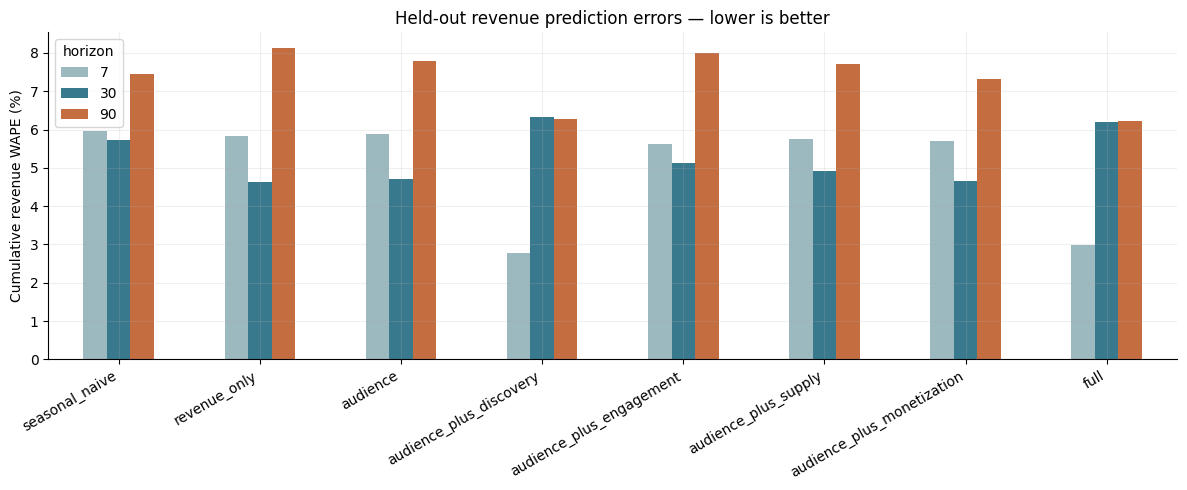

,experiment,reference,horizon,delta_mae,wins,origins,improvement_pct
0,audience,revenue_only,7,162.17,2,4,-0.57
1,audience,revenue_only,30,1795.40,2,4,-1.90
2,audience,revenue_only,90,-21589.56,3,4,4.13
3,audience_plus_supply,audience,7,-536.31,3,4,1.88
4,audience_plus_supply,audience,30,4202.27,1,4,-4.37
5,audience_plus_supply,audience,90,-5790.54,3,4,1.16
6,audience_plus_discovery,audience,7,-15009.35,4,4,52.61
7,audience_plus_discovery,audience,30,32735.11,1,4,-34.01
8,audience_plus_discovery,audience,90,-97295.71,2,4,19.43
9,audience_plus_engagement,audience,7,-1158.29,2,4,4.06


In [6]:
scores, paired = results["scores"], results["paired"]
core = ["seasonal_naive", "revenue_only", "audience", "audience_plus_discovery",
        "audience_plus_engagement", "audience_plus_supply", "audience_plus_monetization", "full"]
comparison = scores[scores.experiment.isin(core)].pivot(index="experiment", columns="horizon", values="cumulative_wape")
display((100 * comparison).round(2).rename_axis(columns="horizon (days), WAPE %"))
ax = (100 * comparison.reindex(core)).plot.bar(figsize=(12, 5), color=["#9cb9bf", "#39798d", "#c46d41"])
ax.set_ylabel("Cumulative revenue WAPE (%)"); ax.set_xlabel("")
ax.set_title("Held-out revenue prediction errors — lower is better")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()
display(paired[~paired.experiment.str.startswith("signals_")].round(2))

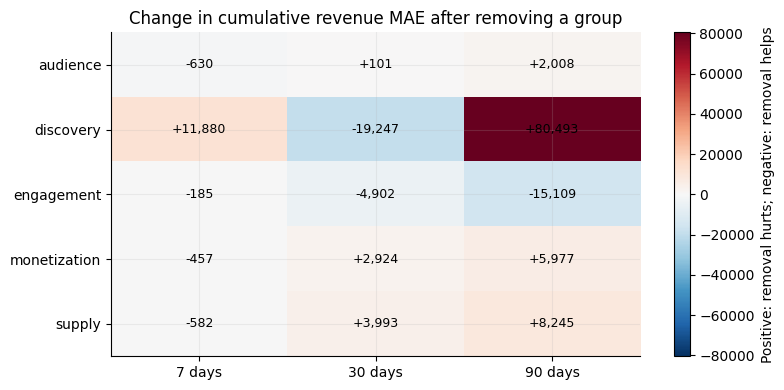

In [7]:
removals = paired[paired.experiment.str.startswith("full_minus_")].copy()
removals["group"] = removals.experiment.str.replace("full_minus_", "", regex=False)
heat = removals.pivot(index="group", columns="horizon", values="delta_mae")
fig, ax = plt.subplots(figsize=(8, 4))
limit = max(float(np.abs(heat.to_numpy()).max()), 1.)
im = ax.imshow(heat, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")
ax.set_yticks(range(len(heat)), heat.index)
ax.set_xticks(range(3), [f"{h} days" for h in heat.columns])
for i in range(len(heat)):
    for j in range(3):
        ax.text(j, i, f"{heat.iloc[i,j]:+,.0f}", ha="center", va="center", fontsize=9)
ax.set_title("Change in cumulative revenue MAE after removing a group")
fig.colorbar(im, ax=ax, label="Positive: removal hurts; negative: removal helps")
plt.tight_layout(); plt.show()

## 4. How early are the signals available?

Delay 7 means the newest discovery/engagement observation is seven days older than the newest revenue observation. Audience remains current. All five variants use the same covariate columns and forecast cutoffs.

A delayed variant that improves upon audience suggests predictive information survives that delay. Comparing it with delay 0 describes sensitivity to freshness. This is not a measured causal response time. Results need many more evaluation origins before identifying a reliable leading indicator.

,delay_days,horizon,improvement_pct,wins,origins
33,0,7,51.02,3,4
36,1,7,59.02,4,4
39,7,7,9.66,3,4
42,14,7,-0.11,3,4
45,30,7,3.84,3,4
34,0,30,-38.03,1,4
37,1,30,-33.21,2,4
40,7,30,-18.26,1,4
43,14,30,-6.25,1,4
46,30,30,-14.90,0,4


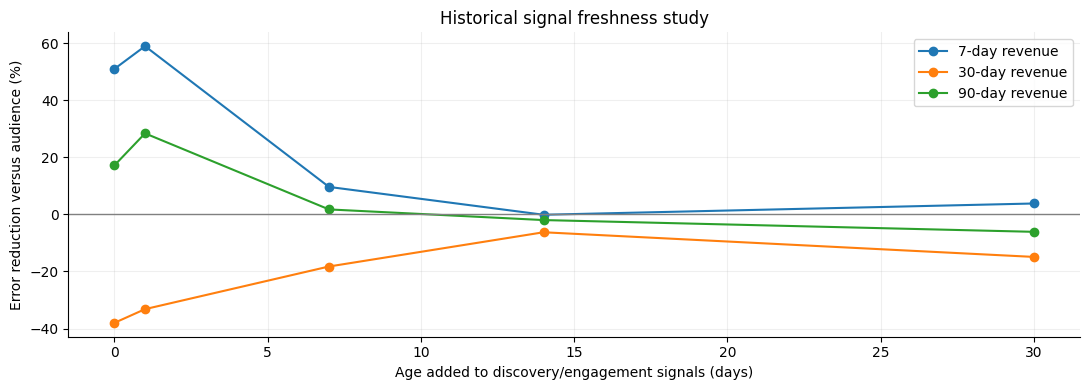

lag_days,0,1,7,14,30
feature,,,,,
ctr,0.048,-0.008,0.237,0.134,-0.065
follow_rate,0.002,0.018,-0.005,0.032,-0.013
repeat_participation_rate,0.154,-0.050,-0.011,0.162,-0.024
room_join_rate,-0.000,-0.023,0.191,0.130,-0.055
views_per_dau,0.448,0.291,0.565,0.493,-0.111
watch_minutes_per_join,0.173,0.007,0.177,-0.016,0.007


In [8]:
delays = paired[paired.experiment.str.startswith("signals_delayed_")].copy()
delays["delay_days"] = delays.experiment.str[-2:].astype(int)
display(delays[["delay_days", "horizon", "improvement_pct", "wins", "origins"]].sort_values(["horizon", "delay_days"]).round(2))
fig, ax = plt.subplots()
for h, rows in delays.groupby("horizon"):
    rows = rows.sort_values("delay_days")
    ax.plot(rows.delay_days, rows.improvement_pct, marker="o", label=f"{h}-day revenue")
ax.axhline(0, color="grey", lw=1)
ax.set(xlabel="Age added to discovery/engagement signals (days)",
       ylabel="Error reduction versus audience (%)", title="Historical signal freshness study")
ax.legend(); plt.tight_layout(); plt.show()

# Descriptive lagged correlations use development data only; levels are differenced.
dev = df.iloc[:635]
associations = []
for feature in GROUPS["discovery"] + GROUPS["engagement"]:
    for lag in [0, 1, 7, 14, 30]:
        associations.append({"feature": feature, "lag_days": lag,
                             "corr_daily_changes": dev[feature].diff().shift(lag).corr(dev.revenue.diff())})
lag_table = pd.DataFrame(associations)
lag_table.to_csv(OUT / "development_lag_correlations.csv", index=False)
display(lag_table.pivot(index="feature", columns="lag_days", values="corr_daily_changes").round(3))

## 5. Calibrate uncertainty for total revenue

Daily marginal quantiles cannot simply be summed into a period-revenue interval. Instead, use the nine **calibration-origin cumulative forecast errors**, normalized by historical median daily revenue × horizon. The 90% finite-sample rank uses the largest of these nine errors. Apply that radius to later origins, without using their outcomes.

These are residual-calibrated intervals with **no guaranteed coverage under time-series dependence or distribution shifts**. Report their measured evaluation coverage and width. Each horizon has its own interval; these are not simultaneous bands.

,coverage,origins,calibration_origins,mean_relative_width
horizon,,,,
7,0.75,4,9,0.105
30,0.50,4,9,0.120
90,0.75,4,9,0.282


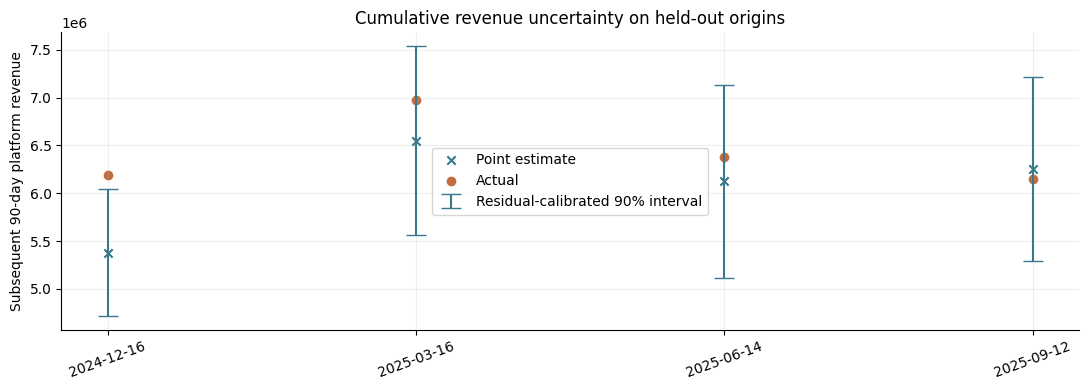

In [9]:
intervals = results["intervals"]
coverage = intervals.groupby("horizon").agg(coverage=("covered", "mean"), origins=("covered", "size"),
                                            calibration_origins=("calibration_origins", "first"))
width = intervals.assign(relative_width=(intervals.upper - intervals.lower) / intervals.actual)
coverage["mean_relative_width"] = width.groupby("horizon").relative_width.mean()
display(coverage.round(3))
rows = intervals[intervals.horizon == 90].sort_values("origin")
x = np.arange(len(rows))
fig, ax = plt.subplots()
# Lower clipping can move the center for plotting; calculate the interval center explicitly.
center = (rows.lower + rows.upper) / 2
ax.errorbar(x, center, yerr=(rows.upper - rows.lower)/2, fmt="none", capsize=7,
            color="#39798d", label="Residual-calibrated 90% interval")
ax.scatter(x, rows.predicted, marker="x", color="#39798d", label="Point estimate")
ax.scatter(x, rows.actual, color="#c46d41", label="Actual")
ax.set_xticks(x, rows.origin.dt.strftime("%Y-%m-%d"), rotation=20)
ax.set(ylabel="Subsequent 90-day platform revenue", title="Cumulative revenue uncertainty on held-out origins")
ax.legend(); plt.tight_layout(); plt.show()

## 6. Flag unusual KPI trajectories

Forecast revenue, DAU, room-join rate and watch time **jointly as targets**, so their future trajectories are produced rather than assumed. These anomaly forecasts are a separate specification from the full covariate revenue model.

Calibrate absolute residuals using the 810 calibration days per metric, normalized by the preceding 28-day median of that metric. Freeze the 95% threshold, then flag evaluation observations outside the calibrated range. Pooled lead times and serial dependence limit interpretation: the nominal level is not a guaranteed alert rate, and there is no multiple-alert correction.

“Unlabelled-day flag rate” below uses synthetic event labels only for retrospective auditing. Labels are approximate affected windows, not perfect anomaly ground truth. A negative deviation indicates performance below the historical forecast, not its cause.

,evaluation_days,flags,empirical_coverage,unlabelled_day_flag_rate,labelled_day_flag_rate
metric,,,,,
dau,360,50,0.861,0.099,0.264
revenue,360,39,0.892,0.048,0.299
room_join_rate,360,3,0.992,0.004,0.023
watch_minutes_per_join,360,2,0.994,0.000,0.023


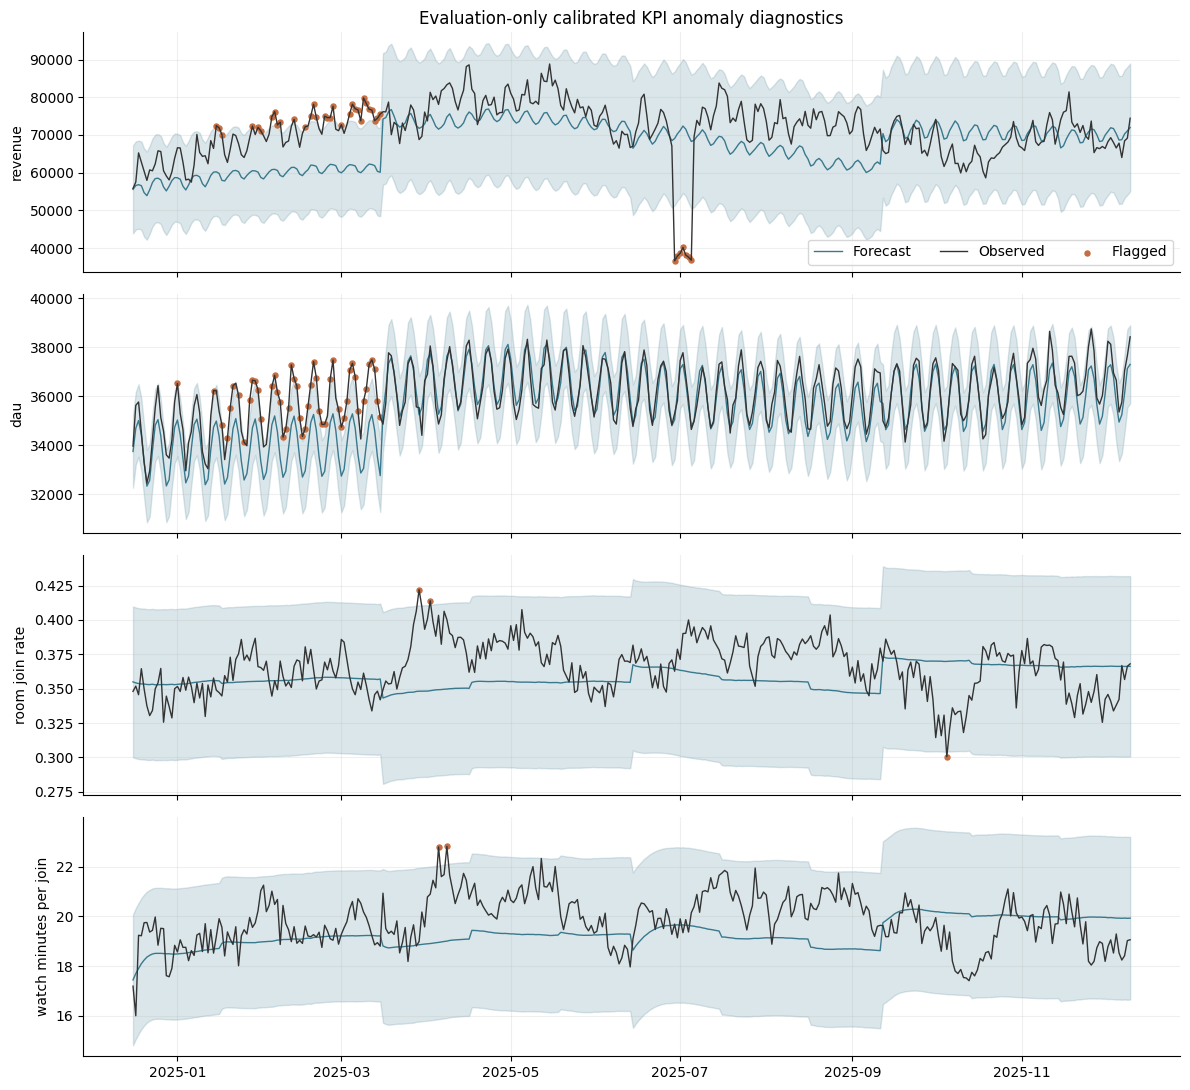

,dt,actual,predicted,lower,upper,event
30,2025-01-15,72490.80,60235.44,48558.37,71912.51,none
31,2025-01-16,71885.03,59803.67,48126.60,71480.74,none
32,2025-01-17,70129.46,57980.72,46303.65,69657.79,none
43,2025-01-28,72358.71,60539.98,48862.91,72217.06,none
45,2025-01-30,72014.09,60171.31,48494.24,71848.38,none
46,2025-01-31,71107.01,58756.79,47079.72,70433.86,none
50,2025-02-04,74877.92,60821.96,49144.89,72499.03,none
51,2025-02-05,76218.57,60900.43,49223.36,72577.50,none
52,2025-02-06,72690.66,60604.80,48927.73,72281.87,none
53,2025-02-07,73393.89,59275.47,47598.40,70952.54,none


In [10]:
anomalies = results["anomalies"]
audit = anomalies.assign(unlabelled=anomalies.event.eq("none"))
alert_summary = audit.groupby("metric").agg(evaluation_days=("flagged", "size"), flags=("flagged", "sum"))
alert_summary["empirical_coverage"] = 1 - audit.groupby("metric").flagged.mean()
alert_summary["unlabelled_day_flag_rate"] = audit[audit.unlabelled].groupby("metric").flagged.mean()
alert_summary["labelled_day_flag_rate"] = audit[~audit.unlabelled].groupby("metric").flagged.mean()
alert_summary.to_csv(OUT / "alert_summary.csv")
display(alert_summary.round(3))
fig, axes = plt.subplots(4, 1, figsize=(12, 11), sharex=True)
for ax, metric in zip(axes, ANOMALY_TARGETS):
    rows = anomalies[anomalies.metric == metric].sort_values("dt")
    ax.fill_between(rows.dt, rows.lower, rows.upper, alpha=.18, color="#39798d")
    ax.plot(rows.dt, rows.predicted, lw=1, color="#39798d", label="Forecast")
    ax.plot(rows.dt, rows.actual, lw=1, color="#333333", label="Observed")
    flagged = rows[rows.flagged]
    ax.scatter(flagged.dt, flagged.actual, color="#c46d41", s=13, label="Flagged")
    ax.set_ylabel(metric.replace("_", " "))
axes[0].legend(ncol=3); axes[0].set_title("Evaluation-only calibrated KPI anomaly diagnostics")
plt.tight_layout(); plt.show()
display(anomalies[(anomalies.metric == "revenue") & anomalies.flagged]
        [["dt", "actual", "predicted", "lower", "upper", "event"]].head(15).round(2))

## 7. Explain an observed revenue change exactly

Compare the synthetic payment-outage start with its preceding day. Average each factor's marginal change over all six possible replacement orders. This symmetric accounting decomposition allocates every interaction and sums exactly to the observed currency change.

It answers how much of the arithmetic change is allocated to audience, conversion, and spend. It does not explain why payer conversion changed. For multi-day comparisons, use compatible weighted period factors rather than multiplying unweighted averages of rates.

2025-06-28 → 2025-06-29: revenue change -30,447.81


,factor,contribution
0,dau,681.22
1,payer_rate,-30694.23
2,revenue_per_payer,-434.80


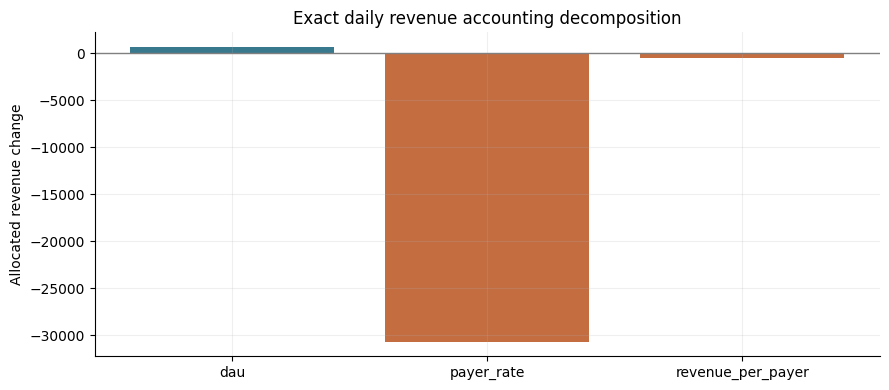

In [11]:
reference, current = df.iloc[1639], df.iloc[1640]
parts = decomposition(reference, current)
observed_change = current.revenue - reference.revenue
np.testing.assert_allclose(parts.contribution.sum(), observed_change, rtol=1e-10)
parts.to_csv(OUT / "accounting_decomposition.csv", index=False)
print(f"{reference['dt'].date()} → {current['dt'].date()}: revenue change {observed_change:,.2f}")
display(parts.round(2))
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(parts.factor, parts.contribution, color=np.where(parts.contribution >= 0, "#39798d", "#c46d41"))
ax.axhline(0, color="grey", lw=1)
ax.set(ylabel="Allocated revenue change", title="Exact daily revenue accounting decomposition")
plt.tight_layout(); plt.show()

## 8. Produce evidence-backed investigation priorities

Join group-addition and group-removal evidence, rather than treating one ablation as a definitive feature ranking. An initial candidate has positive addition improvement and positive removal penalty at the same horizon. Audience is assessed separately against revenue-only.

The table shows negative results too. Four test origins cannot validate the recommendation hypothesis. Use larger chronological evaluations, segment checks and a controlled recommendation experiment before claiming that improving discovery increases revenue.

In [12]:
priorities = []
for group in ["supply", "discovery", "engagement", "monetization"]:
    for h in HORIZONS:
        addition = paired[(paired.experiment == "audience_plus_" + group) & (paired.horizon == h)].iloc[0]
        removal = paired[(paired.experiment == "full_minus_" + group) & (paired.horizon == h)].iloc[0]
        priorities.append({"group": group, "horizon": h,
                           "addition_improvement_pct": addition.improvement_pct,
                           "removal_penalty": removal.delta_mae,
                           "addition_wins": addition.wins, "removal_nonimproving_origins": int(removal.origins - removal.wins),
                           "candidate_for_followup": bool(addition.improvement_pct > 0 and removal.delta_mae > 0)})
priorities = pd.DataFrame(priorities)
priorities.to_csv(OUT / "investigation_priorities.csv", index=False)
display(priorities.round(2))
best = scores[scores.horizon == 30].sort_values("cumulative_wape").iloc[0]
print(f"Descriptive result: lowest 30-day WAPE in this fixed evaluation was {best.experiment}: {best.cumulative_wape:.1%}.")
print("This comparison does not select or validate a production model.")
candidates = priorities[priorities.candidate_for_followup]
if candidates.empty:
    print("No group passed both exploratory criteria. Do not invent a positive driver finding.")
else:
    print("Exploratory follow-up candidates:", "; ".join(f"{r.group} ({r.horizon} days)" for r in candidates.itertuples()))
print("Next business step: test a recommendation change with randomized assignment, revenue and retention outcomes,")
print("and content-supply/monetization guardrails. This notebook estimates no intervention effect.")

# Final analytical checks accompany the actual pretrained-model execution.
assert len(results["forecasts"]) == 16 * (len(specs) + 1) * 3
assert results["forecasts"].groupby(["experiment", "horizon"]).size().eq(16).all()
assert intervals.calibration_origins.eq(9).all()
assert anomalies.groupby("metric").size().eq(360).all()
assert np.isfinite(results["forecasts"][["actual", "predicted", "abs_error"]]).all().all()
print("All origin/horizon, calibration and accounting checks passed.")

,group,horizon,addition_improvement_pct,removal_penalty,addition_wins,removal_nonimproving_origins,candidate_for_followup
0,supply,7,1.88,-582.12,3,2,False
1,supply,30,-4.37,3993.26,1,4,False
2,supply,90,1.16,8244.98,3,3,True
3,discovery,7,52.61,11879.90,4,4,True
4,discovery,30,-34.01,-19247.12,1,1,False
5,discovery,90,19.43,80492.79,2,2,True
6,engagement,7,4.06,-184.58,2,1,False
7,engagement,30,-8.57,-4901.80,1,0,False
8,engagement,90,-2.50,-15109.22,2,1,False
9,monetization,7,3.08,-456.60,3,1,False


Descriptive result: lowest 30-day WAPE in this fixed evaluation was revenue_only: 4.6%.
This comparison does not select or validate a production model.
Exploratory follow-up candidates: supply (90 days); discovery (7 days); discovery (90 days); monetization (30 days); monetization (90 days)
Next business step: test a recommendation change with randomized assignment, revenue and retention outcomes,
and content-supply/monetization guardrails. This notebook estimates no intervention effect.
All origin/horizon, calibration and accounting checks passed.


## Reuse with real platform data

Replace `make_sample()` with an as-of daily extract using the documented column definitions. Reconcile revenue with finance, audit event availability timestamps, and distinguish missing observations from real zeros. Use real unique-user counts; the synthetic expected counts here are only for demonstration.

Revisit context length, the calendar, data sufficiency and rolling splits before applying the helper to another date range. The supplied study has a fixed five-year demonstration schedule. Keep an untouched future evaluation period when changing specifications. Estimate uncertainty across enough independent periods and repeat the comparison across regions/cohorts. Historical monetization can dominate other inputs, so inspect additions/removals together.

Artifacts include the sample CSV, origin-level forecasts and splits, paired errors, calibrated intervals, daily anomaly evidence, reporting windows, lag associations, decomposition and investigation priorities. `manifest.json` records the seed, model checkpoint revision, Python executable and package versions.